# Programa 11. Evaluación de clasificación

Noviembre 15, 2026

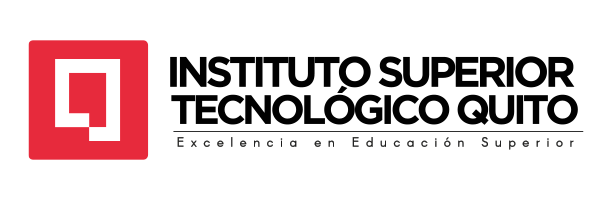

**Nombre:** Edgar Ulloa  
**Fecha:** *15-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

## Evaluación de clasificación

**Objetivo:** Evaluar un modelo de clasificación SVM con el dataset Iris, utilizando una partición externa de entrenamiento y prueba con una validación cruzada interna de cinco particiones.

## Importación de librerías

Se importan las siguientes librerias:
- **numpy:** Realiza operaciones numéricas.
- **train_test_split:** Sirva para realizar la separación de entrenamiento y de prueba.
- **cross_val_predict y KFold:** Realiza las predicciones mediante validación cruzada.
- **StandardScaler:** Realiza la estandarización de los atributos.
- **SVC:** Es un algoritmo de clasificación basado en máquinas de vectores de soporte.
- **Pipeline:** Sirve para aplicar el escalamiento dentro de cada partición, evitando fugas de información.

In [1]:
import numpy as np
from pprint import pprint
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

## Carga del conjunto Iris

El dataset Iris contiene 150 instancias, 4 atributos numéricos que detallan ciertas medidas de las flores y 3 clases. **datos.data** contiene las medidas y **datos.target** contiene la clase a predecir.

In [2]:
datos = datasets.load_iris()
print("Dimensiones del conjunto de datos:", np.shape(datos.data))
print("Atributos:", datos.feature_names)
print("Clases:", datos.target_names)

Dimensiones del conjunto de datos: (150, 4)
Atributos: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']


## Separación de atributos y clase objetivo

La variable **X** contiene los atributos que utiliza el modelo para aprender y la variable **y** contiene las etiquetas correctas de las especies.

In [3]:
X = datos.data
y = datos.target
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


## Partición externa: 80% entrenamiento y 20% prueba

Se reserva el 20% de las instancias para evaluar el modelo al final y el 80% restante se usa en el entrenamiento y la validación cruzada, **random_state=42** permite repetir la misma partición, **stratify=y** mantiene aproximadamente la proporción de las tres clases en ambos conjuntos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

Dimensiones de entrenamiento: (120, 4)
Dimensiones de prueba: (30, 4)


## Estandarización de atributos

El programa **StandardScaler** transforma cada atributo del dataset para que tenga una media cercana a 0 y una desviación estándar cercana a 1 en el conjunto usado para ajustarlo.

In [5]:
standardizer = StandardScaler()
X_train_scaled = standardizer.fit_transform(X_train)
X_test_scaled = standardizer.transform(X_test)
print("Primer registro original:", X_train[0])
print("Primer registro estandarizado:", np.round(X_train_scaled[0], 4))

Primer registro original: [4.4 2.9 1.4 0.2]
Primer registro estandarizado: [-1.7216 -0.3321 -1.3457 -1.3233]


## Definición del algoritmo SVM

Se utiliza el modelo **SVC** con los parámetros del ejercicio original: C=0.1, gamma='auto' y kernel='rbf'.

En este código se definen estos para:
- **C** controlar la penalización de errores de clasificación.
- **gamma** regular la influencia de cada instancia en el kernel RBF.
- **kernel='rbf'** permitir establecer fronteras de decisión no lineales.
- **Pipeline** reúne el escalamiento y el clasificador.

In [7]:
alg = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", SVC(C=0.1, gamma="auto", kernel="rbf"))
])
print(alg)

Pipeline(steps=[('escalador', StandardScaler()),
                ('clasificador', SVC(C=0.1, gamma='auto'))])


## Validación cruzada interna: cinco particiones

En el proceso de validación cruzada **KFold(n_splits=5)** divide las 120 instancias de entrenamiento en cinco grupos, para que en cada iteración, el modelo aprenda con cuatro grupos y de una prediccion con el quinto. **cross_val_predict** reúne las predicciones de las cinco iteraciones, de modo que cada instancia de entrenamiento tenga una predicción obtenida cuando estuvo en el grupo de validación. Se define **shuffle=True** y **random_state=42** para obtener las mezclas de forma reproducible.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(alg, X_train, y_train, cv=cv)
print("Predicciones obtenidas en la validación cruzada:")
pprint(y_pred)
print("Total de predicciones:", len(y_pred))

Predicciones obtenidas en la validación cruzada:
array([0, 1, 2, 0, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 0, 0, 2, 2, 0, 1, 0,
       2, 0, 1, 2, 2, 0, 1, 0, 0, 1, 1, 0, 2, 2, 1, 1, 2, 1, 0, 2, 0, 2,
       0, 0, 1, 0, 0, 0, 0, 1, 2, 1, 0, 1, 1, 2, 0, 1, 0, 1, 1, 0, 1, 1,
       2, 1, 1, 2, 0, 0, 0, 1, 1, 2, 1, 2, 1, 1, 0, 2, 1, 0, 2, 0, 2, 1,
       2, 0, 1, 2, 0, 0, 2, 2, 2, 1, 1, 0, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1,
       0, 2, 1, 1, 0, 0, 0, 0, 2, 0])
Total de predicciones: 120


##Métricas de evaluación interna

Se ha definido las siguientes métricas de evaluación:

- **Exactitud (accuracy):** Devuelve la proporción total de predicciones correctas.
- **Precisión (precision):** Devuelve la propoción que realmente pertenece a una clase predicha.
- **Sensibilidad (recall):** Devuelve la proporcion que se identifica correctamente entre las instancias que realmente pertenecen a una clase.
- **F1-score:** Combina la precisión y la sensibilidad mediante su media armónica.

Como Iris tiene tres clases, **average='macro'** calcula la métrica para cada clase y después obtiene un promedio sin ponderar entre ellas, los valores próximos a 1 indican un mejor desempeño.

In [9]:
print("Exactitud: %.3f" % metrics.accuracy_score(y_train, y_pred))
print("Precisión: %.3f" % metrics.precision_score(y_train, y_pred, average="macro", zero_division=0))
print("Sensibilidad: %.3f" % metrics.recall_score(y_train, y_pred, average="macro", zero_division=0))
print("F1-score: %.3f" % metrics.f1_score(y_train, y_pred, average="macro", zero_division=0))

Exactitud: 0.875
Precisión: 0.882
Sensibilidad: 0.875
F1-score: 0.874


## Matriz de confusión de la validación cruzada

La matriz de confusión compara clases reales (instancias) con clases predichas (atributos). Los valores presentados en la diagonal principal representan los aciertos y los valores fuera de la diagonal representan confusiones entre especies.

In [10]:
print("Orden de las clases:", list(datos.target_names))
print("Matriz de confusión:\n", metrics.confusion_matrix(y_train, y_pred))

Orden de las clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Matriz de confusión:
 [[40  0  0]
 [ 0 36  4]
 [ 0 11 29]]


## Informe de clasificación

La funcón **classification_report** presenta las métricas precisión, sensibilidad y F1-score para cada especie. También muestra **support**, valor que indica cuántas instancias reales hay de cada clase y los promedios generales.

In [11]:
print("Informe de clasificación (validación cruzada):")
print(metrics.classification_report(y_train, y_pred, target_names=datos.target_names, zero_division=0))

Informe de clasificación (validación cruzada):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        40
  versicolor       0.77      0.90      0.83        40
   virginica       0.88      0.72      0.79        40

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.87       120
weighted avg       0.88      0.88      0.87       120



## Entrenamiento del modelo definitivo y evaluación externa

Una vez revisadas las métricas internas, se entrena un nuevo modelo utilizando las 120 instancias de entrenamiento, para luego medir su exactitud sobre las 30 instancias de prueba que permanecieron separadas.

In [12]:
model = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", SVC(C=0.1, gamma="auto", kernel="rbf"))
])
model = model.fit(X_train, y_train)
test_results = model.score(X_test, y_test)
print("Exactitud en test:", np.round(test_results * 100, 4), "%")

Exactitud en test: 90.0 %


## Predicciones y métricas sobre el conjunto de prueba

La función **predict()** genera las clases estimadas para las 30 instancias reservadas, el informe permite conocer el rendimiento por especie y la matriz de confusión identifica los aciertos y errores.

In [13]:
y_pred_test = model.predict(X_test)
print("Informe de clasificación (prueba):")
print(metrics.classification_report(
    y_test, y_pred_test, target_names=datos.target_names, zero_division=0
))
print("Matriz de confusión (prueba):")
print(metrics.confusion_matrix(y_test, y_pred_test))

Informe de clasificación (prueba):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

Matriz de confusión (prueba):
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


Si la exactitud es 0.90, significa que el modelo clasificó correctamente el 90% de las instancias del conjunto evaluado.

## Comprobaciones finales

Se comprueba que las predicciones internas tengan el mismo número de elementos que **y_train**, que las predicciones externas corresponden a **y_test** y que la exactitud calculada coincida con la reportada por **score()**.

In [14]:
assert len(y_pred) == len(y_train)
assert len(y_pred_test) == len(y_test)
assert np.isclose(test_results, metrics.accuracy_score(y_test, y_pred_test))
print("Comprobaciones correctas: las dimensiones y la exactitud coinciden.")

Comprobaciones correctas: las dimensiones y la exactitud coinciden.


## Conclusión

En este ejercicio se aplicó un clasificador **SVM con kernel RBF** al conjunto de datos Iris, el primer paso fue reservar el 20% de las instancias para una evaluación final y se utilizó el 80% restante para el entrenamiento y la validación cruzada de cinco particiones.

La validación cruzada permitió calcular la métricas de exactitud, precisión, sensibilidad y F1-score sin utilizar los datos de prueba y la matriz de confusión permitió identificar qué especies fueron clasificadas correctamente y cuáles se confundieron.

Finalmente, se entrenó el modelo con todas las instancias del conjunto de entrenamiento y se evaluó con los datos de prueba, el escalamiento de los datos se incorporó dentro de un **Pipeline** para evitar fugas de información.

En conclusión la evaluación interna ayudo a estimar el desempeño del clasificador durante su desarrollo, mientras que la evaluación externa permitió comprobar su comportamiento en instancias que no se utilizaron para entrenarlo.